In [47]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('../data/olist.db')
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

# carregando só o necessário
orders = pd.read_sql("""
    SELECT o.customer_id, c.customer_unique_id,
           o.order_purchase_timestamp, oi.price
    FROM orders o
    JOIN customers c ON o.customer_id = c.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
""", conn)

orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

print(f'Shape: {orders.shape}')
orders.head()

Shape: (110197, 4)


,customer_id,customer_unique_id,order_purchase_timestamp,price
0,9ef432eb6251297304e76186b10a928d,7c396fd4830fd04220f754e42b4e5bff,2017-10-02 10:56:33,29.99
1,b0830fb4747a6c6d20dea0b8c802d7ef,af07308b275d755c9edb36a90c618231,2018-07-24 20:41:37,118.70
2,41ce2a54c0b03bf3443c3d931a367089,3a653a41f6f9fc3d2a113cf8398680e8,2018-08-08 08:38:49,159.90
3,f88197465ea7920adcdbec7375364d82,7c142cf63193a1473d2e66489a9ae977,2017-11-18 19:28:06,45.00
4,8ab97904e6daea8866dbdbc4fb7aad2c,72632f0f9dd73dfee390c9b22eb56dd6,2018-02-13 21:18:39,19.90


In [48]:
data_referencia = orders['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

In [49]:
recencia = (orders
    .groupby('customer_unique_id')['order_purchase_timestamp']
    .max()
    .reset_index()
)
recencia['recencia_dias'] = (data_referencia - recencia['order_purchase_timestamp']).dt.days
recencia = recencia[['customer_unique_id', 'recencia_dias']]

In [50]:
frequencia = (orders
    .groupby('customer_unique_id')['order_purchase_timestamp']
    .count()
    .reset_index()
)
frequencia.columns = ['customer_unique_id', 'frequencia']

In [51]:
monetario = (orders
    .groupby('customer_unique_id')['price']
    .sum()
    .reset_index()
)
monetario.columns = ['customer_unique_id', 'monetario']

In [52]:
rfm = (recencia
    .merge(frequencia, on='customer_unique_id')
    .merge(monetario, on='customer_unique_id')
)

print(rfm.shape)
rfm.head()

(93358, 4)


,customer_unique_id,recencia_dias,frequencia,monetario
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00


In [53]:
rfm['R'] = pd.qcut(rfm['recencia_dias'], q=5, labels=[5,4,3,2,1])

In [54]:
rfm['F'] = pd.qcut(rfm['frequencia'].rank(method='first'), q=5, labels=[1,2,3,4,5])

In [55]:
rfm['M'] = pd.qcut(rfm['monetario'], q=5, labels=[1,2,3,4,5])

In [56]:
rfm['rfm_score'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)


In [57]:
print(rfm[['recencia_dias', 'frequencia', 'monetario', 'R', 'F', 'M', 'rfm_score']].head(10))

   recencia_dias  frequencia  monetario  R  F  M rfm_score
0            112           1     129.90  4  1  4       414
1            115           1      18.90  4  1  1       411
2            537           1      69.00  1  1  2       112
3            321           1      25.99  2  1  1       211
4            288           1     180.00  2  1  5       215
5            146           1     154.00  4  1  4       414
6            132           1      27.99  4  1  1       411
7            183           2     382.00  3  5  5       355
8            543           1     135.00  1  1  4       114
9            170           1     104.90  4  1  3       413


In [58]:
def segmentar(row):
    r, f, m = int(row['R']), int(row['F']), int(row['M'])
    
    if r >= 4 and f >= 4 and m >= 4:
        return 'Campeões'
    elif r >= 3 and f >= 3:
        return 'Clientes Fiéis'
    elif r >= 4 and f <= 2:
        return 'Novos Clientes'
    elif r <= 2 and f >= 3:
        return 'Em Risco'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Hibernando'
    else:
        return 'Potencial'

rfm['segmento'] = rfm.apply(segmentar, axis=1)

print(rfm['segmento'].value_counts())

segmento
Clientes Fiéis    26799
Em Risco          22276
Potencial         15537
Novos Clientes    14983
Campeões           6940
Hibernando         6823
Name: count, dtype: int64


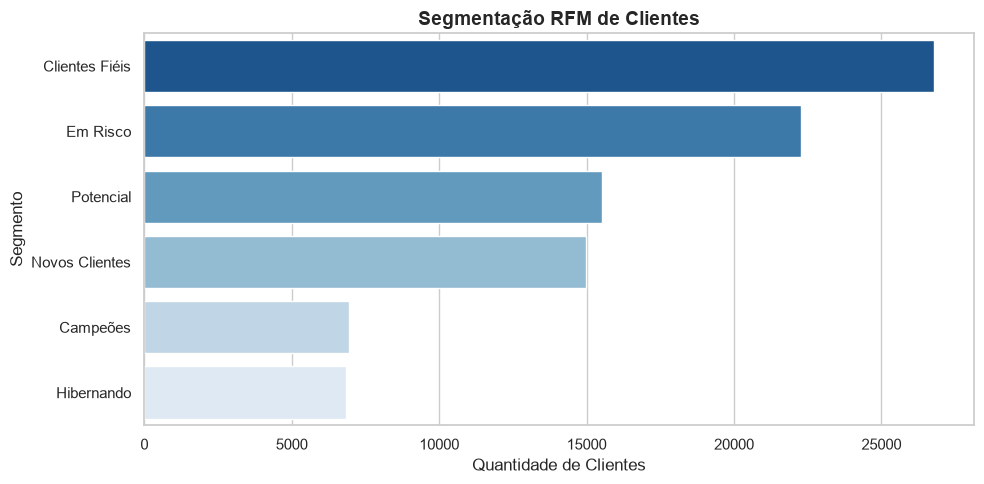

                clientes  recencia_media  frequencia_media  monetario_medio
segmento                                                                   
Clientes Fiéis     26799           145.0               1.2            113.0
Em Risco           22276           394.4               1.3            149.4
Potencial          15537           311.6               1.0            169.8
Novos Clientes     14983            90.6               1.0            133.7
Campeões            6940            91.5               1.7            280.3
Hibernando          6823           396.9               1.0             40.9


In [59]:
# Gráfico: distribuição dos segmentos
segmentos = rfm['segmento'].value_counts().reset_index()
segmentos.columns = ['segmento', 'quantidade']

plt.figure(figsize=(10, 5))
sns.barplot(data=segmentos, x='quantidade', y='segmento',
            hue='segmento', palette='Blues_r', legend=False,
            order=segmentos['segmento'])
plt.title('Segmentação RFM de Clientes', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de Clientes')
plt.ylabel('Segmento')
plt.tight_layout()
plt.savefig('../outputs/rfm_segmentos.png', dpi=150)
plt.show()

# tabela resumo por segmento
resumo = rfm.groupby('segmento').agg(
    clientes=('customer_unique_id', 'count'),
    recencia_media=('recencia_dias', 'mean'),
    frequencia_media=('frequencia', 'mean'),
    monetario_medio=('monetario', 'mean')
).round(1).sort_values('clientes', ascending=False)

print(resumo)